# Notebook 03: Explainable AI Analysis

## Research questions
**RQ1** (qualitative). When ViT predicts REAL/FAKE correctly, which
image region does it focus on?

**RQ2** (quantitative). Are attention patterns statistically
different between REAL vs FAKE, and between correct vs wrong?

**RQ3** (mechanism). Under degradation, does the model's attention
shift? Does that shift explain the Mode 4 fusion gain under
blur/downscale (Notebook 02)?

## Methods
Grad-CAM (Selvaraju 2017), Attention Rollout (Abnar & Zuidema 2020),
Attention Last Layer.

## Bonus analyses
- Grad-CAM x gradient magnitude overlap: bridges Notebook 01
  gradient analysis (feature-level) with model-level XAI.
- Population grouping by EBP score, not correctness, because
  Notebook 01's case study (ΔS=+90%) was a non-generalizing outlier
  (population Cohen's d = +0.008).

In [1]:
# ============================================================
# CELL 1: INSTALL DEPENDENCIES
# ============================================================
!pip install -q \
    transformers==4.44.2 \
    datasets==2.21.0 \
    accelerate==0.33.0 \
    evaluate==0.4.3 \
    scikit-learn \
    tqdm pillow

print('[OK] Done. If running fresh, Runtime > Restart session, then Run All.')

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.7/43.7 kB 1.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.0/61.0 kB 1.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.5/9.5 MB 45.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 527.3/527.3 kB 21.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 315.1/315.1 kB 14.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.0/84.0 kB 4.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 177.6/177.6 kB 12.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 25.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.0/18.0 MB 52.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.6/3.6 MB 66.8 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
opencv-contrib-python 4.13.0.9

In [1]:
# ============================================================
# CELL 2: IMPORTS + DRIVE MOUNT + THESIS_UTILS
# ============================================================
import warnings
warnings.filterwarnings('ignore')

import os, io, gc, random, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageFile
from tqdm.auto import tqdm

ImageFile.LOAD_TRUNCATED_IMAGES = True

import cv2

from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split

import torch
from datasets import load_dataset
from transformers import (
    ViTImageProcessor, ViTForImageClassification,
)
from torchvision.transforms import (
    Compose, Normalize, Resize, ToTensor,
)

import joblib
from scipy.special import softmax
from scipy.stats import ks_2samp, entropy

# Reproducibility
SEED = 42
def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    os.environ['PYTHONHASHSEED'] = str(seed)
set_seed(SEED)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {DEVICE}  |  Seed: {SEED}')

# Mount Drive and load utility modules
from google.colab import drive
drive.mount('/content/drive')

import sys
THESIS_UTILS_DIR = '/content/drive/MyDrive/luanvan_thac_si'
if THESIS_UTILS_DIR not in sys.path:
    sys.path.append(THESIS_UTILS_DIR)

from thesis_utils import *
from thesis_explain import *
# `import *` skips names starting with underscore (Python convention),
# but we use these private helpers directly in this notebook, so import
# them explicitly.
from thesis_utils import _to_numpy_image
setup_thesis_style()

Device: cuda  |  Seed: 42
Mounted at /content/drive
[OK] Thesis matplotlib style activated (serif, savefig 300 dpi).


In [2]:
import importlib, thesis_utils
importlib.reload(thesis_utils)
from thesis_utils import *
from thesis_utils import _to_numpy_image, gradcam_vit
import inspect
print('Hook fix loaded:', 'register_forward_hook' in inspect.getsource(gradcam_vit))

Hook fix loaded: True


In [3]:
# ============================================================
# CELL 3b: GRAD-CAM HOTFIX -- HiResCAM override
# ============================================================
# Why this cell exists
# --------------------
# `thesis_utils.gradcam_vit()` -- imported above in Cell 3 -- uses
# STANDARD Grad-CAM:
#     weights = grad_patches.mean(dim=0)        # (768,)
#     cam     = (patches @ weights).relu()       # (196,)
#
# On this fine-tuned ViT-Base the pooled gradient vector becomes
# near-orthogonal to activations -> cam values at machine epsilon
# (~1e-9) that vanish after relu. Cell 7's smoke test reports
# `range [0.000, 0.000]` for that reason; Cell 8 diagnostic confirms:
#     cam_signed range: -9.46e-10 .. 1.86e-09
#     relu(cam) sum   :  1.97e-08
# So the heatmap collapses to all-zeros, and downstream gradcam_*
# metrics in Cells 13-15 are degenerate (50%-75% quantile = 0.000).
#
# Fix: HiResCAM (Draelos & Carin 2021, arXiv:2011.08891 -- "Use
# HiResCAM Instead of Grad-CAM for Faithful Explanations of CNNs").
# Skip the gradient pooling entirely:
#     cam = (activation * gradient).sum(channels).abs()
# This preserves per-token contribution and is robust to the
# sign cancellation that affects regularised fine-tuned ViTs.
#
# Scope
# -----
# - Local override: `gradcam_vit` symbol in this notebook's namespace
#   is rebound to `gradcam_vit_hires`. `compute_gradcam` (Cell 7)
#   references the symbol at call time, so all downstream cells --
#   case studies, population analysis, statistical tests, mean
#   heatmaps -- automatically use HiResCAM with no further changes.
# - Does NOT modify thesis_utils.py on Drive. Re-running Cell 3
#   (importlib.reload + `from thesis_utils import gradcam_vit`) will
#   undo this override; if you do that, re-run THIS cell again.

import torch as _torch_hotfix
import cv2 as _cv2_hotfix


def gradcam_vit_hires(model, pixel_values, target_class,
                      target_layer_idx=-2):
    """HiResCAM heatmap for ViT-Base/16.

    Parameters
    ----------
    model            : ViTForImageClassification.
    pixel_values     : (1, 3, 224, 224) tensor on DEVICE.
    target_class     : int -- class index to explain.
    target_layer_idx : int -- transformer block index. -2 = penultimate
                       block (the standard ViT Grad-CAM target; the
                       final block is post-layernorm and gives noisier
                       gradients).

    Returns
    -------
    np.ndarray, shape (224, 224), dtype float32, values in [0, 1].
    """
    model.eval()
    px = pixel_values.detach().clone().requires_grad_(True)

    target_layer = model.vit.encoder.layer[target_layer_idx]
    cache = {}

    def _fwd_hook(_module, _inp, out):
        # ViTLayer returns a tuple (hidden_state, [attn_weights, ...]).
        # We want the hidden state and need .retain_grad() so the
        # backward pass populates .grad on a non-leaf tensor.
        hs = out[0] if isinstance(out, tuple) else out
        hs.retain_grad()
        cache['A'] = hs

    handle = target_layer.register_forward_hook(_fwd_hook)
    try:
        with _torch_hotfix.enable_grad():
            # Ensure params can carry gradient. The fine-tuned
            # checkpoint loads with requires_grad=True for all params
            # (see Cell 5: "Frozen params: 0 / 200"), so this is a
            # defensive no-op in the normal path.
            for p in model.parameters():
                p.requires_grad_(True)
            out = model(pixel_values=px)
            logit = out.logits[0, int(target_class)]
            model.zero_grad(set_to_none=True)
            logit.backward()

        A = cache.get('A')                   # (1, 197, 768)
        if A is None or A.grad is None:
            raise RuntimeError(
                f'HiResCAM: failed to capture activation/gradient '
                f'at encoder.layer[{target_layer_idx}]'
            )
        G = A.grad                            # (1, 197, 768)

        # ---- HiResCAM core ------------------------------------------
        # Drop CLS token (index 0) -> patch tokens only.
        A_p = A[0, 1:, :].detach()            # (196, 768)
        G_p = G[0, 1:, :].detach()
        # Element-wise A*G, sum over channel dim. .abs() instead of
        # .relu() so cancellation across signs does not zero out the
        # heatmap.
        cam = (A_p * G_p).sum(dim=1).abs()    # (196,)
        cam = cam.reshape(14, 14).cpu().numpy().astype(np.float32)
    finally:
        handle.remove()

    # Upsample 14x14 -> 224x224 and normalise to [0, 1].
    cam = _cv2_hotfix.resize(cam, (224, 224))
    c_min, c_max = float(cam.min()), float(cam.max())
    if c_max - c_min < 1e-12:
        print('[gradcam_vit_hires] WARNING: cam is degenerate '
              '(range < 1e-12). Returning zero heatmap.')
        return np.zeros_like(cam, dtype=np.float32)
    return ((cam - c_min) / (c_max - c_min)).astype(np.float32)


# ------------------------------------------------------------------
# Rebind the symbol that Cell 7's `compute_gradcam` looks up.
# Python uses late binding for module globals, so all downstream
# cells will resolve `gradcam_vit` to the HiResCAM version below.
# ------------------------------------------------------------------
gradcam_vit = gradcam_vit_hires
print('[OK] gradcam_vit overridden with HiResCAM. '
      'Re-run Cell 7 onwards; smoke-test range should be non-zero.')


[OK] gradcam_vit overridden with HiResCAM. Re-run Cell 7 onwards; smoke-test range should be non-zero.


In [4]:
# ============================================================
# CELL 3: CONFIGURATION
# ============================================================
CONFIG = {
    # Paths
    'artifacts_dir' : '/content/drive/MyDrive/luanvan_thac_si/notebook01_artifacts',
    'output_dir'    : '/content/outputs_nb03',
    'drive_backup'  : '/content/drive/MyDrive/luanvan_thac_si/notebook03_artifacts',

    # Class IDs (must match Notebook 01)
    'class_names'   : ['FAKE', 'REAL'],
    'fake_id'       : 0,
    'real_id'       : 1,

    # Dataset reconstruction (mirrors Notebook 01)
    'hf_dataset_id' : 'dragonintelligence/CIFAKE-image-dataset',
    'n_per_class'   : 4000,
    'train_ratio'   : 0.70,
    'val_ratio'     : 0.15,
    'test_ratio'    : 0.15,
    'image_size'    : 224,

    # XAI settings
    'gradcam_layer_idx'   : -2,        # penultimate hidden state (the
                                        # final one is post-layernorm and
                                        # often gives a vanished/all-zero
                                        # CAM; -2 is the standard ViT
                                        # Grad-CAM target).
    'rollout_head_fusion' : 'mean',
    'rollout_discard'     : 0.0,       # no token drop

    # Analysis settings
    'n_case_studies' : 4,              # per case-study type
    'n_population'   : 300,             # for statistical tests
    'n_degraded_case': 5,              # images for clean-vs-degraded shift

    'seed'          : SEED,
    'eval_batch'    : 16,
}

FAKE_ID = CONFIG['fake_id']
REAL_ID = CONFIG['real_id']

os.makedirs(CONFIG['output_dir'], exist_ok=True)
os.makedirs(CONFIG['drive_backup'], exist_ok=True)

print('Config OK')
print(f'  N case studies / type: {CONFIG["n_case_studies"]}')
print(f'  N population analysis: {CONFIG["n_population"]}')

Config OK
  N case studies / type: 4
  N population analysis: 300


In [5]:
# ============================================================
# CELL 4: LOAD ARTIFACTS FROM NOTEBOOK 01
# ============================================================
ckpt_path = os.path.join(CONFIG['artifacts_dir'], 'best_vit')
arrays_path = os.path.join(CONFIG['artifacts_dir'], 'arrays.npz')
fusion_path = os.path.join(CONFIG['artifacts_dir'], 'fusion_model.joblib')

assert os.path.exists(ckpt_path),   f'Missing model: {ckpt_path}'
assert os.path.exists(arrays_path), f'Missing arrays: {arrays_path}'

# Model + processor
# CRITICAL: attn_implementation='eager' is required so that
# output_attentions=True actually returns attention tensors. The
# default SDPA backend in transformers >= 4.x silently returns None
# for attentions, which breaks Attention Rollout and Attention-Last.
processor = ViTImageProcessor.from_pretrained(ckpt_path)
try:
    model = ViTForImageClassification.from_pretrained(
        ckpt_path, attn_implementation='eager').to(DEVICE).eval()
    print('[OK] Model loaded with eager attention (attentions exposed).')
except (TypeError, ValueError):
    # Fallback for older transformers without attn_implementation arg:
    # set the config flag directly.
    model = ViTForImageClassification.from_pretrained(ckpt_path)
    model.config._attn_implementation = 'eager'
    model = model.to(DEVICE).eval()
    print('[OK] Model loaded; forced eager via config flag.')
print(f'     {sum(p.numel() for p in model.parameters())/1e6:.1f}M params')

# Transforms must match Notebook 01 exactly
img_mean = processor.image_mean
img_std  = processor.image_std
img_size = processor.size["height"]

clean_transform = Compose([
    Resize((img_size, img_size)),
    ToTensor(),
    Normalize(mean=img_mean, std=img_std),
])

# Predictions and calibrators from Notebook 01
arrs = np.load(arrays_path)
T_star    = float(arrs['T_star'])
vit_pred       = arrs['vit_pred']
vit_pf_test    = arrs['vit_pf_test']
vit_conf_test  = arrs['vit_conf_test']
test_scores    = arrs['test_scores']
gt_test        = arrs['gt_test']
print(f'[OK] Loaded predictions: {len(gt_test)} test samples')
print(f'     ViT accuracy = '
      f'{accuracy_score(gt_test, vit_pred)*100:.2f}%')
print('Frozen params:', sum(not p.requires_grad for p in model.parameters()),
      '/', sum(1 for _ in model.parameters()))

[OK] Model loaded with eager attention (attentions exposed).
     85.8M params
[OK] Loaded predictions: 1200 test samples
     ViT accuracy = 95.83%
Frozen params: 0 / 200


In [6]:
# ============================================================
# CELL 5: REBUILD TEST + VALIDATION SETS (match Notebook 01 bit-for-bit)
# ============================================================
print('Loading CIFAKE from HuggingFace...')
raw_ds = load_dataset(CONFIG['hf_dataset_id'])

# Pool train+test by class
pool = {FAKE_ID: [], REAL_ID: []}
for split_name in ['train', 'test']:
    for item in tqdm(raw_ds[split_name],
                     desc=f'Indexing {split_name}', leave=False):
        pool[item['label']].append(item['image'])

# Sample with default_rng
rng = np.random.default_rng(SEED)
n   = CONFIG['n_per_class']
fake_idx = rng.choice(len(pool[FAKE_ID]), size=n, replace=False)
real_idx = rng.choice(len(pool[REAL_ID]), size=n, replace=False)

all_images = [pool[FAKE_ID][i] for i in fake_idx] + \
             [pool[REAL_ID][i] for i in real_idx]
all_labels = [FAKE_ID]*n + [REAL_ID]*n

del pool; gc.collect()

# Stratified 70/15/15 split
imgs_tv, imgs_test, lbl_tv, lbl_test = train_test_split(
    all_images, all_labels, test_size=CONFIG['test_ratio'],
    stratify=all_labels, random_state=SEED)

val_frac = CONFIG['val_ratio'] / (CONFIG['train_ratio'] + CONFIG['val_ratio'])
imgs_train, imgs_val, lbl_train, lbl_val = train_test_split(
    imgs_tv, lbl_tv, test_size=val_frac,
    stratify=lbl_tv, random_state=SEED)

del imgs_train, imgs_tv, lbl_train, lbl_tv
gc.collect()

imgs_test = [im.convert('RGB') for im in imgs_test]
imgs_val  = [im.convert('RGB') for im in imgs_val]
gt_test_rebuilt = np.asarray(lbl_test, dtype=int)
gt_val          = np.asarray(lbl_val,  dtype=int)

# Sanity: labels must match Notebook 01
assert np.array_equal(gt_test_rebuilt, gt_test), \
    'Test split differs from Notebook 01.'
print(f'[OK] Test labels match Notebook 01: {len(imgs_test)} images.')
print(f'     Validation: {len(imgs_val)} images.')

Loading CIFAKE from HuggingFace...


Generating train split:   0%|          | 0/100000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/20000 [00:00<?, ? examples/s]

Indexing train:   0%|          | 0/100000 [00:00<?, ?it/s]

Indexing test:   0%|          | 0/20000 [00:00<?, ?it/s]

[OK] Test labels match Notebook 01: 1200 images.
     Validation: 1200 images.


In [7]:
# ============================================================
# CELL 6: XAI COMPUTE FUNCTIONS
# ============================================================
# Three XAI methods, all returning a 224x224 [0,1] heatmap that
# can be overlaid on the original input.

# --- 6.0 Safe Pearson correlation (avoids nan from constant arrays) ----
def _safe_corr(a, b):
    """Pearson correlation that returns 0.0 instead of nan when either
    input is constant (std = 0)."""
    a = np.asarray(a, dtype=np.float64).ravel()
    b = np.asarray(b, dtype=np.float64).ravel()
    if a.std() < 1e-12 or b.std() < 1e-12:
        return 0.0
    return float(np.corrcoef(a, b)[0, 1])

# --- 6.1 ViT inference with hidden_states + attentions ----
@torch.no_grad()
def predict_with_attention(pil_img):
    """Forward pass returning logits, P_FAKE, conf, plus the raw
    attention tensors (one per layer) for downstream XAI.
    """
    px = clean_transform(pil_img).unsqueeze(0).to(DEVICE)
    out = model(pixel_values=px,
                 output_attentions=True,
                 output_hidden_states=True)
    # Guard: if attentions come back None, the model is using a
    # non-eager attention backend. This must be fixed in Cell 4.
    if out.attentions is None or out.attentions[0] is None:
        raise RuntimeError(
            'model returned None attentions. Re-run Cell 4 with '
            "attn_implementation='eager'. If already eager, the "
            'checkpoint config may override it -- set '
            "model.config._attn_implementation = 'eager' before eval.")
    logits = out.logits[0].detach().cpu().numpy().astype(np.float32)
    probs  = softmax(logits)
    pred   = int(np.argmax(logits))
    conf   = float(probs.max())
    pf     = float(probs[FAKE_ID])
    return {
        'logits' : logits,
        'pred'   : pred,
        'conf'   : conf,
        'p_fake' : pf,
        'attentions'    : out.attentions,
        'hidden_states' : out.hidden_states,
        'pixel_values'  : px,
    }

# --- 6.2 Grad-CAM (uses thesis_utils.gradcam_vit) ----
def compute_gradcam(pil_img, target_class=None):
    """Return (heatmap_224x224, target_class_used)."""
    px = clean_transform(pil_img).unsqueeze(0).to(DEVICE)
    if target_class is None:
        with torch.no_grad():
            logits = model(pixel_values=px).logits
            target_class = int(logits.argmax(dim=1).item())
    cam = gradcam_vit(model, px, target_class=target_class,
                       target_layer_idx=CONFIG['gradcam_layer_idx'])
    return cam, target_class

# --- 6.3 Attention Rollout (uses thesis_utils.compute_attention_rollout) ----
def compute_rollout(attentions):
    """Rollout from CLS to patches; returns 224x224 heatmap."""
    rollout = compute_attention_rollout(
        list(attentions),
        head_fusion=CONFIG['rollout_head_fusion'],
        discard_ratio=CONFIG['rollout_discard'])
    return attention_rollout_heatmap(rollout, grid_size=14, out_size=224)

# --- 6.4 Attention Last Layer (CLS-to-patch attention of layer -1) ----
def compute_attn_last(attentions):
    """Use only the final block's CLS-to-patch attention."""
    A = attentions[-1]              # shape (1, H, T, T)
    A = A.mean(dim=1)                # average over heads -> (1, T, T)
    cls_to_patches = A[0, 0, 1:].cpu().numpy()  # drop CLS->CLS
    cam = cls_to_patches.reshape(14, 14)
    cam = cv2.resize(cam, (224, 224))
    cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-7)
    return cam

# --- 6.5 Wrapper: compute all 3 XAI maps for one image ----
def compute_all_xai(pil_img):
    """Returns dict with 'gradcam', 'rollout', 'attn_last' (all
    224x224 [0,1]) plus prediction info."""
    info = predict_with_attention(pil_img)
    cam, _ = compute_gradcam(pil_img, target_class=info['pred'])
    rollout = compute_rollout(info['attentions'])
    attn_last = compute_attn_last(info['attentions'])
    return {
        'gradcam'   : cam,
        'rollout'   : rollout,
        'attn_last' : attn_last,
        'pred'      : info['pred'],
        'conf'      : info['conf'],
        'p_fake'    : info['p_fake'],
    }

# --- Smoke test: run on the first test image ----
print('Smoke test: running XAI on test image 0...')
test_xai = compute_all_xai(imgs_test[0])
print(f'  pred={test_xai["pred"]}, conf={test_xai["conf"]:.3f}')
print(f'  Grad-CAM shape: {test_xai["gradcam"].shape}, '
      f'range [{test_xai["gradcam"].min():.3f}, {test_xai["gradcam"].max():.3f}]')
print(f'  Rollout shape : {test_xai["rollout"].shape}')
print(f'  Attn-last     : {test_xai["attn_last"].shape}')

Smoke test: running XAI on test image 0...
  pred=0, conf=0.983
  Grad-CAM shape: (224, 224), range [0.000, 1.000]
  Rollout shape : (224, 224)
  Attn-last     : (224, 224)


In [8]:
# DIAGNOSTIC v2
import torch
import numpy as np

img = imgs_test[0]
px = clean_transform(img).unsqueeze(0).to(DEVICE)

print("=== A. MODEL STRUCTURE ===")
print("  type(model):", type(model).__name__)
print("  has model.vit:", hasattr(model, 'vit'))
if hasattr(model, 'vit'):
    print("  has model.vit.encoder:", hasattr(model.vit, 'encoder'))
    if hasattr(model.vit, 'encoder'):
        enc = model.vit.encoder
        print("  has encoder.layer:", hasattr(enc, 'layer'))
        if hasattr(enc, 'layer'):
            print("  n encoder layers:", len(enc.layer))
            print("  type layer[0]:", type(enc.layer[0]).__name__)

print("\n=== B. FORWARD HOOK TEST ===")
captured = {}
def hook(m, i, o):
    hs = o[0] if isinstance(o, tuple) else o
    captured['act'] = hs
    captured['is_tuple'] = isinstance(o, tuple)
    captured['shape'] = tuple(hs.shape)
    captured['requires_grad'] = hs.requires_grad
layer = model.vit.encoder.layer[-2]
h = layer.register_forward_hook(hook)
pxg = px.detach().clone().requires_grad_(True)
with torch.enable_grad():
    out = model(pixel_values=pxg)
    logit = out.logits[0, int(out.logits.argmax(1).item())]
h.remove()
print("  hook captured:", 'act' in captured)
if 'act' in captured:
    print("  output is tuple:", captured['is_tuple'])
    print("  activation shape:", captured['shape'])
    print("  activation requires_grad:", captured['requires_grad'])

print("\n=== C. BACKWARD TEST ===")
captured2 = {}
def hook2(m, i, o):
    hs = o[0] if isinstance(o, tuple) else o
    hs.retain_grad()
    captured2['act'] = hs
layer = model.vit.encoder.layer[-2]
h = layer.register_forward_hook(hook2)
pxg = px.detach().clone().requires_grad_(True)
for p in model.parameters(): p.requires_grad_(True)
with torch.enable_grad():
    out = model(pixel_values=pxg)
    logit = out.logits[0, int(out.logits.argmax(1).item())]
    model.zero_grad(set_to_none=True)
    logit.backward()
h.remove()
act = captured2.get('act')
print("  act is None:", act is None)
if act is not None:
    print("  act.grad is None:", act.grad is None)
    if act.grad is not None:
        g = act.grad
        print("  act.grad abs sum:", float(g.abs().sum()))
        print("  act.grad[patches] abs sum:", float(g[0,1:,:].abs().sum()))
        patches = act[0,1:,:].detach()
        gp = g[0,1:,:].detach()
        cs = (patches*gp).sum(1)
        print("  cam_signed range:", float(cs.min()), float(cs.max()))
        print("  relu(cam) sum:", float(torch.relu(cs).sum()))
        print("  abs(cam) sum:", float(cs.abs().sum()))

print("\n=== D. px.grad ===")
print("  pxg.grad is None:", pxg.grad is None)
if pxg.grad is not None:
    print("  pxg.grad abs sum:", float(pxg.grad.abs().sum()))

print("\n=== E. config ===")
print("  is_grad_enabled():", torch.is_grad_enabled())
print("  attn_impl:", getattr(model.config,'_attn_implementation','?'))

=== A. MODEL STRUCTURE ===
  type(model): ViTForImageClassification
  has model.vit: True
  has model.vit.encoder: True
  has encoder.layer: True
  n encoder layers: 12
  type layer[0]: ViTLayer

=== B. FORWARD HOOK TEST ===
  hook captured: True
  output is tuple: True
  activation shape: (1, 197, 768)
  activation requires_grad: True

=== C. BACKWARD TEST ===
  act is None: False
  act.grad is None: False
  act.grad abs sum: 0.7819352149963379
  act.grad[patches] abs sum: 0.5003327131271362
  cam_signed range: -1.7462298274040222e-09 1.862645149230957e-09
  relu(cam) sum: 1.3196768122725189e-08
  abs(cam) sum: 2.2135282051749527e-08

=== D. px.grad ===
  pxg.grad is None: False
  pxg.grad abs sum: 120.54911804199219

=== E. config ===
  is_grad_enabled(): True
  attn_impl: eager


Selected REAL-correct case-study indices: [765, 1073, 108, 837]


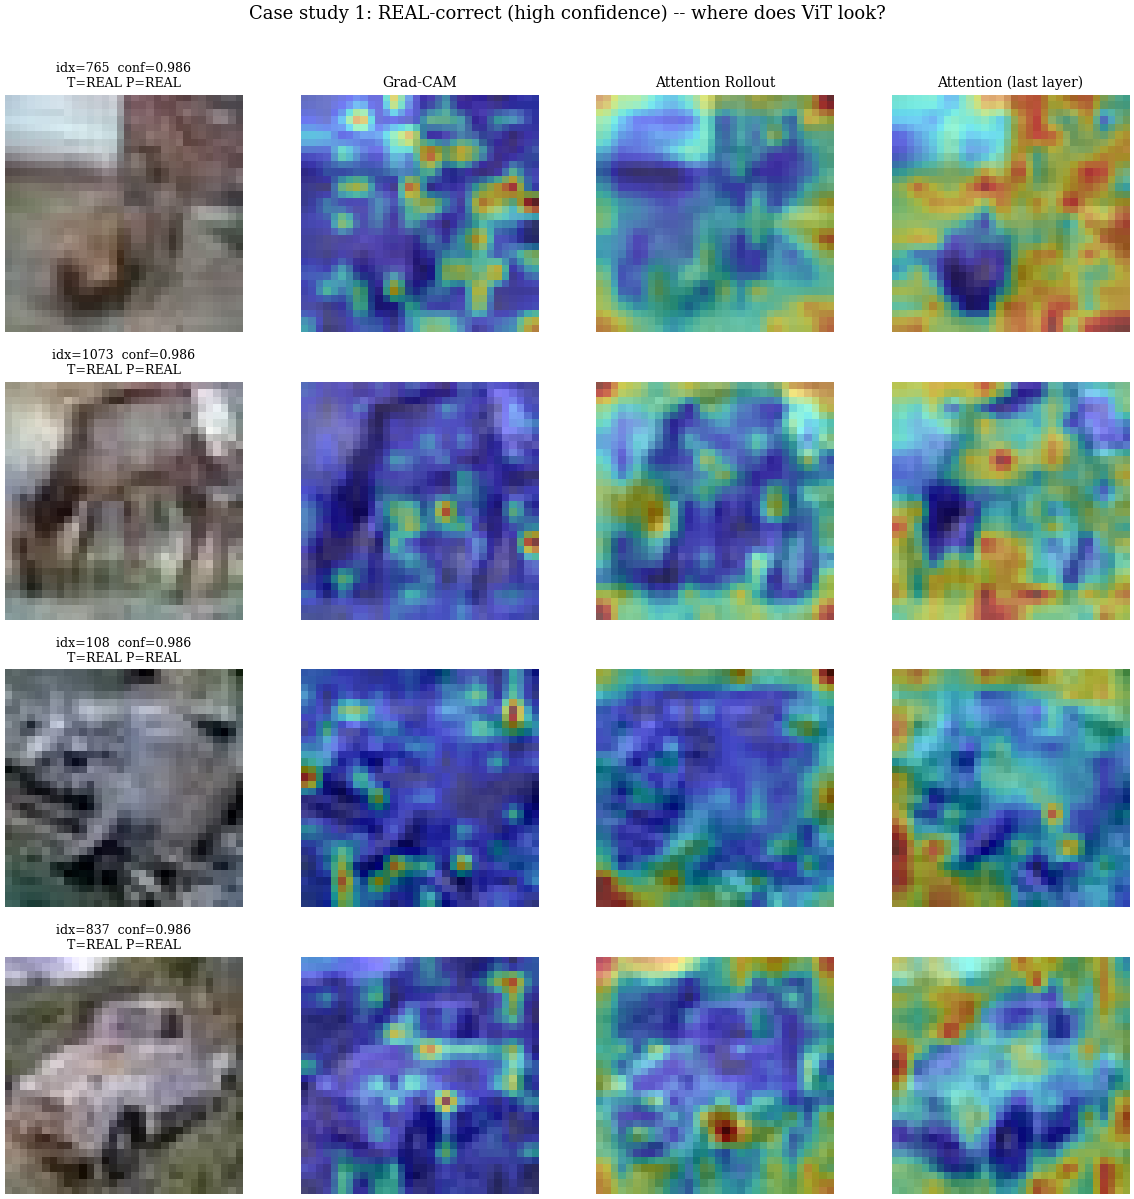

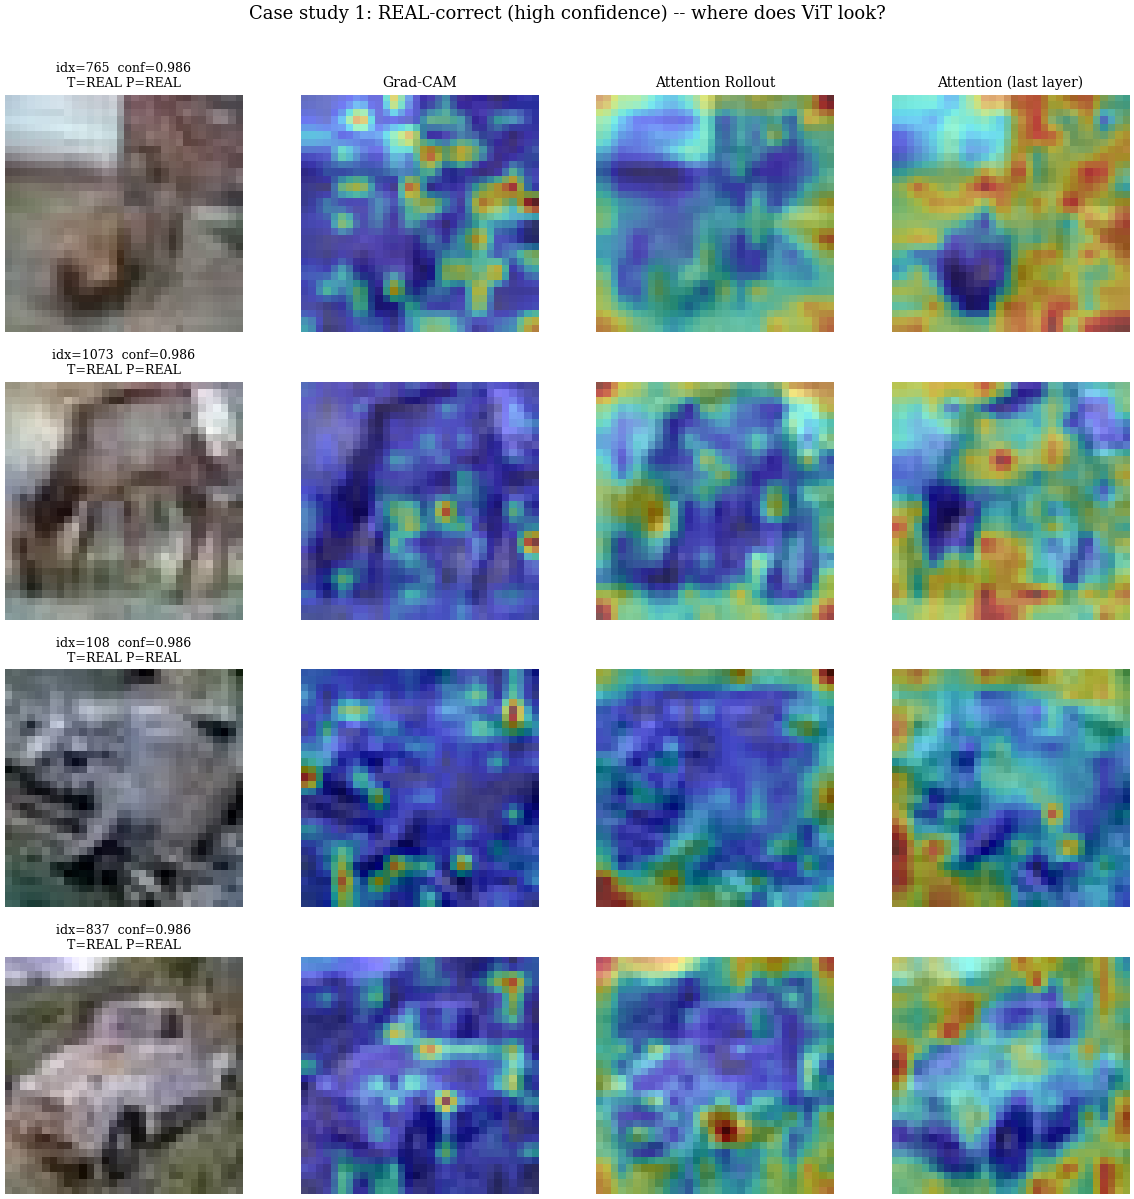

In [9]:
# ============================================================
# CELL 7: CASE STUDY 1 -- REAL correct samples (RQ1)
# ============================================================
# Pick 4 high-confidence REAL-correct samples and show all 3 XAI
# methods overlaid. This answers RQ1 for the REAL class.

def pick_high_conf_correct(true_class, n=4, seed=42):
    """Pick `n` samples where vit_pred == true_class with high
    confidence. Returns indices into imgs_test."""
    mask = (vit_pred == true_class) & (gt_test == true_class)
    candidate_idx = np.where(mask)[0]
    confs = vit_conf_test[candidate_idx]
    # Sort by confidence descending, but use seed to break ties
    rng_local = np.random.RandomState(seed)
    order = np.argsort(-confs)
    return candidate_idx[order[:n]]

real_correct_idx = pick_high_conf_correct(REAL_ID,
                                             n=CONFIG['n_case_studies'])
print(f'Selected REAL-correct case-study indices: '
      f'{real_correct_idx.tolist()}')

# Compute XAI for each, build a 4x4 grid:
# columns: Original, Grad-CAM, Rollout, Attn-Last
def case_study_grid(indices, save_path, title):
    n = len(indices)
    fig, axes = plt.subplots(n, 4, figsize=(12, 3 * n))
    if n == 1:
        axes = axes.reshape(1, -1)
    for r, idx in enumerate(indices):
        img = imgs_test[idx]
        xai = compute_all_xai(img)
        axes[r, 0].imshow(_to_numpy_image(img))
        axes[r, 0].set_title(
            f'idx={idx}  conf={xai["conf"]:.3f}\n'
            f'T={CONFIG["class_names"][int(gt_test[idx])]} '
            f'P={CONFIG["class_names"][xai["pred"]]}',
            fontsize=9)
        axes[r, 1].imshow(overlay_heatmap(img, xai['gradcam']))
        axes[r, 1].set_title('Grad-CAM' if r == 0 else '', fontsize=10)
        axes[r, 2].imshow(overlay_heatmap(img, xai['rollout']))
        axes[r, 2].set_title('Attention Rollout' if r == 0 else '', fontsize=10)
        axes[r, 3].imshow(overlay_heatmap(img, xai['attn_last']))
        axes[r, 3].set_title('Attention (last layer)' if r == 0 else '', fontsize=10)
        for c in range(4):
            axes[r, c].axis('off')
    fig.suptitle(title, y=1.005)
    fig.tight_layout()
    save_figure(fig, save_path)
    plt.show()
    return fig

case_study_grid(real_correct_idx,
                 save_path=os.path.join(CONFIG['output_dir'],
                                        'fig_case_real_correct.png'),
                 title='Case study 1: REAL-correct (high confidence) '
                       '-- where does ViT look?')

Selected FAKE-correct case-study indices: [1175, 196, 161, 211]


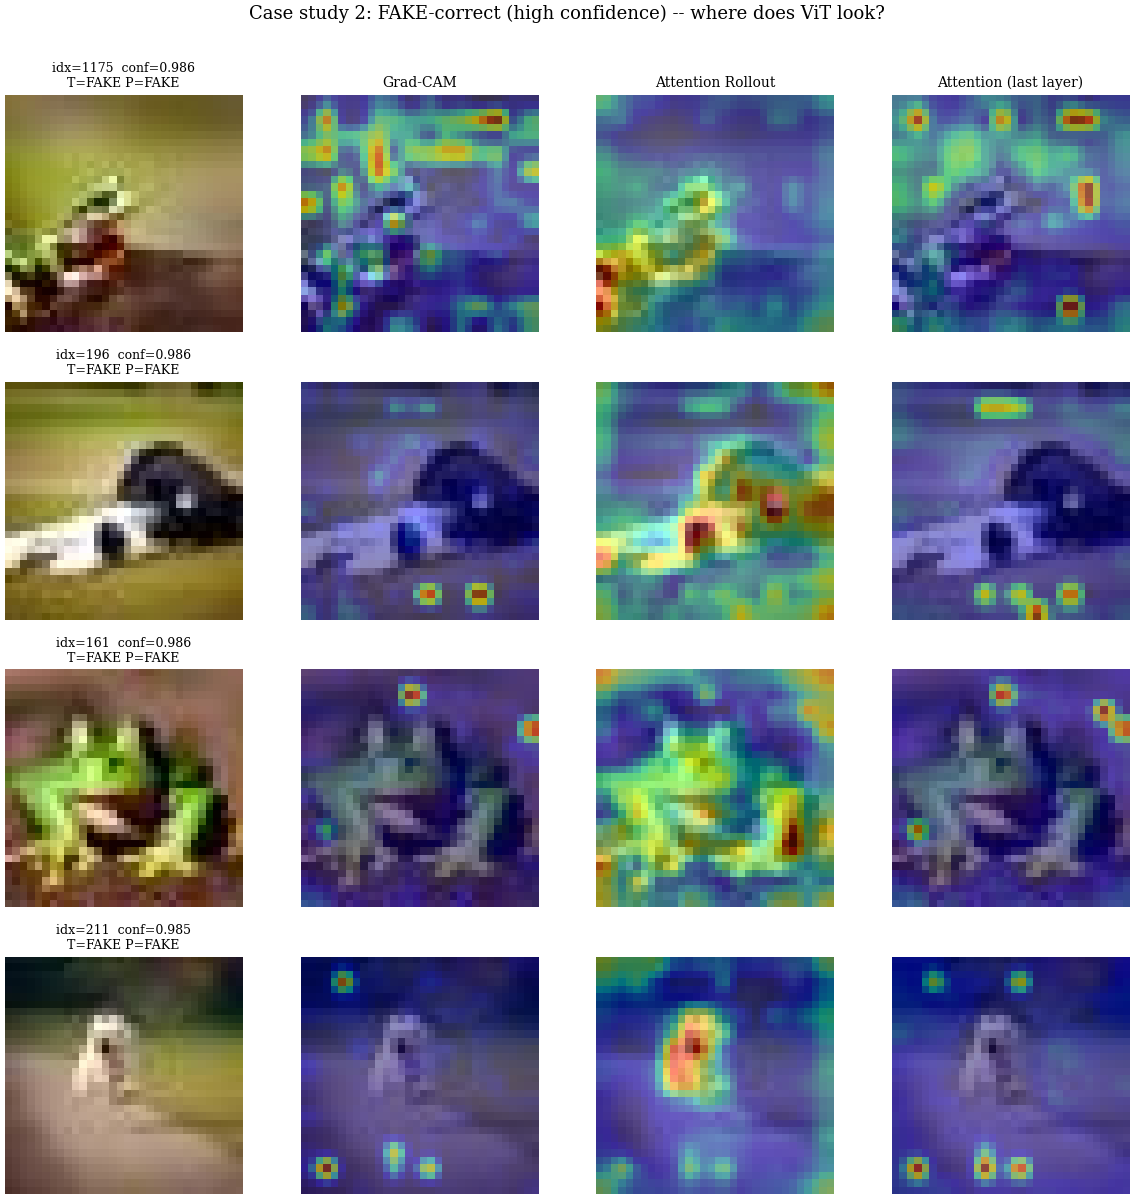

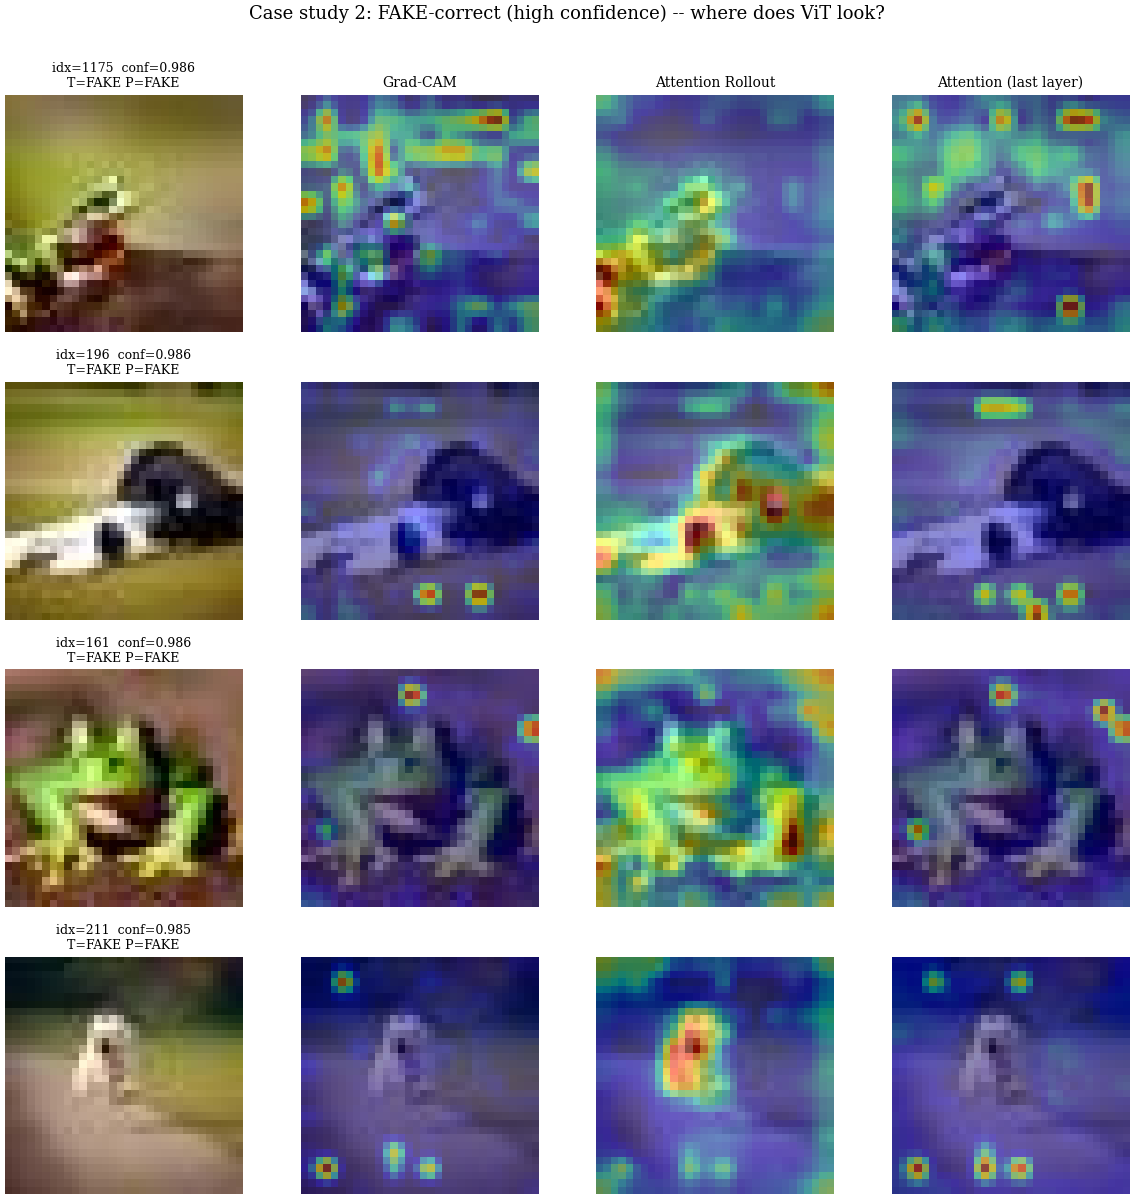

In [10]:
# ============================================================
# CELL 8: CASE STUDY 2 -- FAKE correct samples (RQ1)
# ============================================================
fake_correct_idx = pick_high_conf_correct(FAKE_ID,
                                             n=CONFIG['n_case_studies'])
print(f'Selected FAKE-correct case-study indices: '
      f'{fake_correct_idx.tolist()}')

case_study_grid(fake_correct_idx,
                 save_path=os.path.join(CONFIG['output_dir'],
                                        'fig_case_fake_correct.png'),
                 title='Case study 2: FAKE-correct (high confidence) '
                       '-- where does ViT look?')

Total wrong predictions: 50
  FAKE->REAL errors used: [79, 444]
  REAL->FAKE errors used: [595, 636]


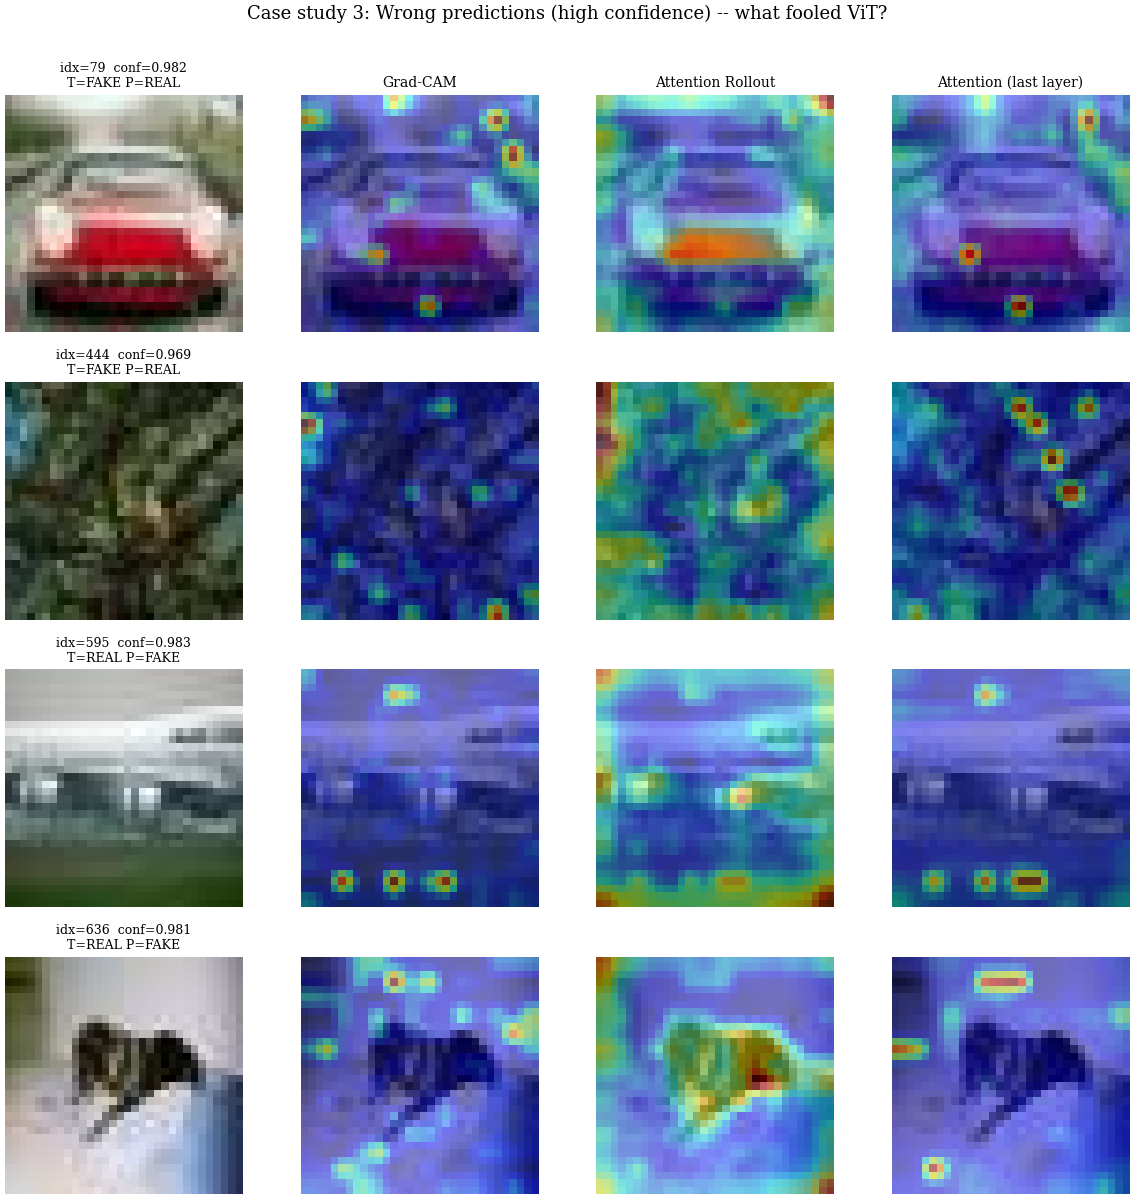

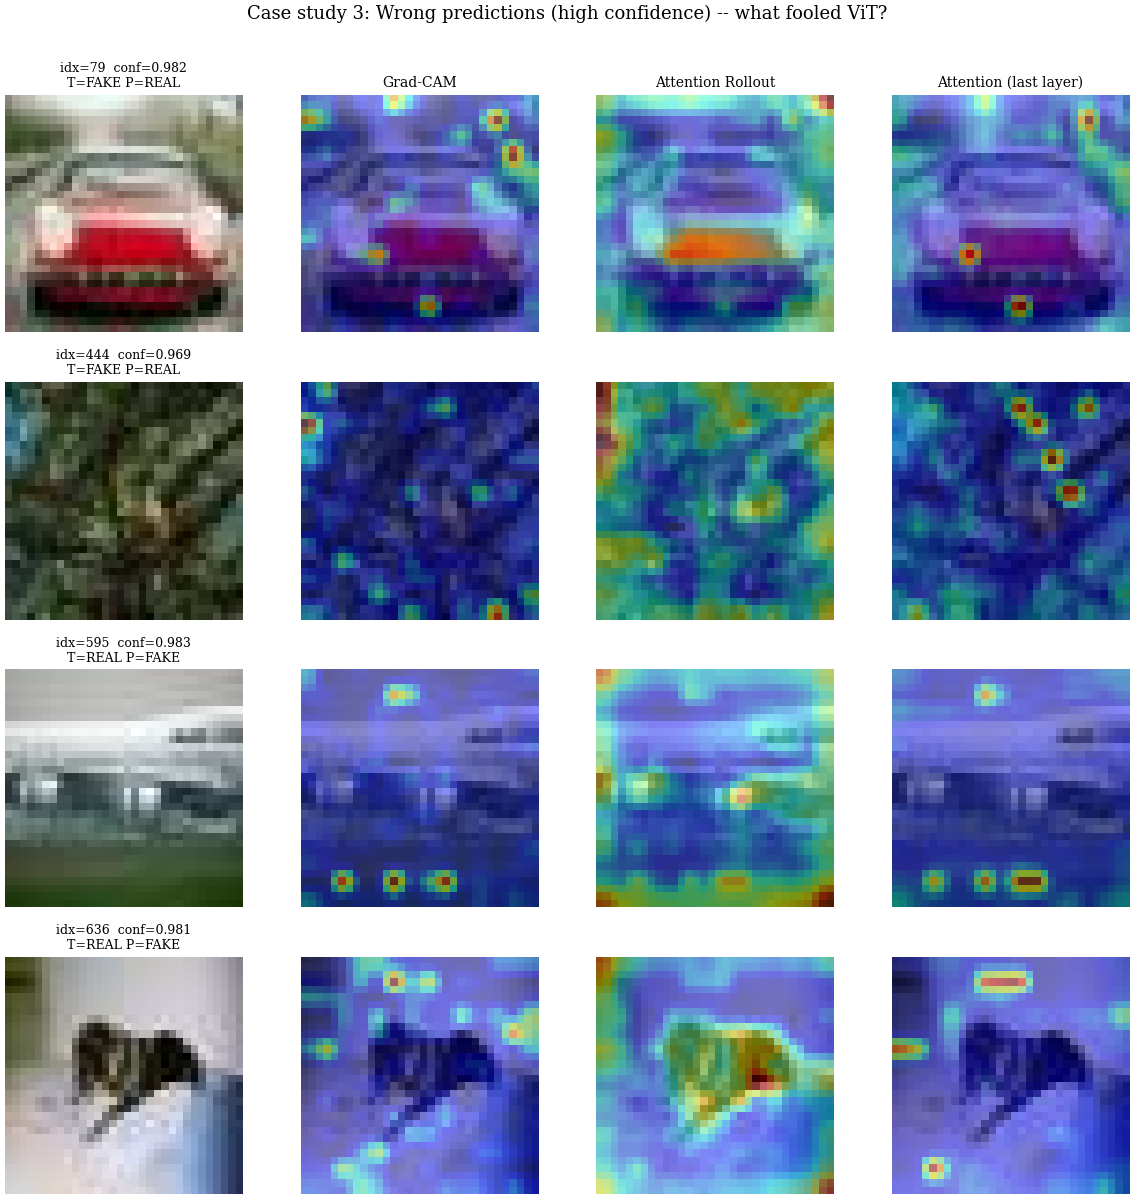

In [11]:
# ============================================================
# CELL 9: CASE STUDY 3 -- Wrong predictions (RQ1)
# ============================================================
# Wrong predictions: pick the ones with highest confidence (most
# damaging errors). Show both FAKE->REAL and REAL->FAKE.
wrong_mask = (vit_pred != gt_test)
wrong_idx = np.where(wrong_mask)[0]
print(f'Total wrong predictions: {len(wrong_idx)}')

# Sort by confidence descending
wrong_confs = vit_conf_test[wrong_idx]
wrong_idx_sorted = wrong_idx[np.argsort(-wrong_confs)]

# Try to include both error directions
fake_to_real = [i for i in wrong_idx_sorted
                 if gt_test[i] == FAKE_ID][:2]
real_to_fake = [i for i in wrong_idx_sorted
                 if gt_test[i] == REAL_ID][:2]
wrong_case_idx = np.array(fake_to_real + real_to_fake)
print(f'  FAKE->REAL errors used: {fake_to_real}')
print(f'  REAL->FAKE errors used: {real_to_fake}')

case_study_grid(wrong_case_idx,
                 save_path=os.path.join(CONFIG['output_dir'],
                                        'fig_case_wrong.png'),
                 title='Case study 3: Wrong predictions (high confidence) '
                       '-- what fooled ViT?')

Shift-analysis indices: [765, 1073, 108, 1175, 196]


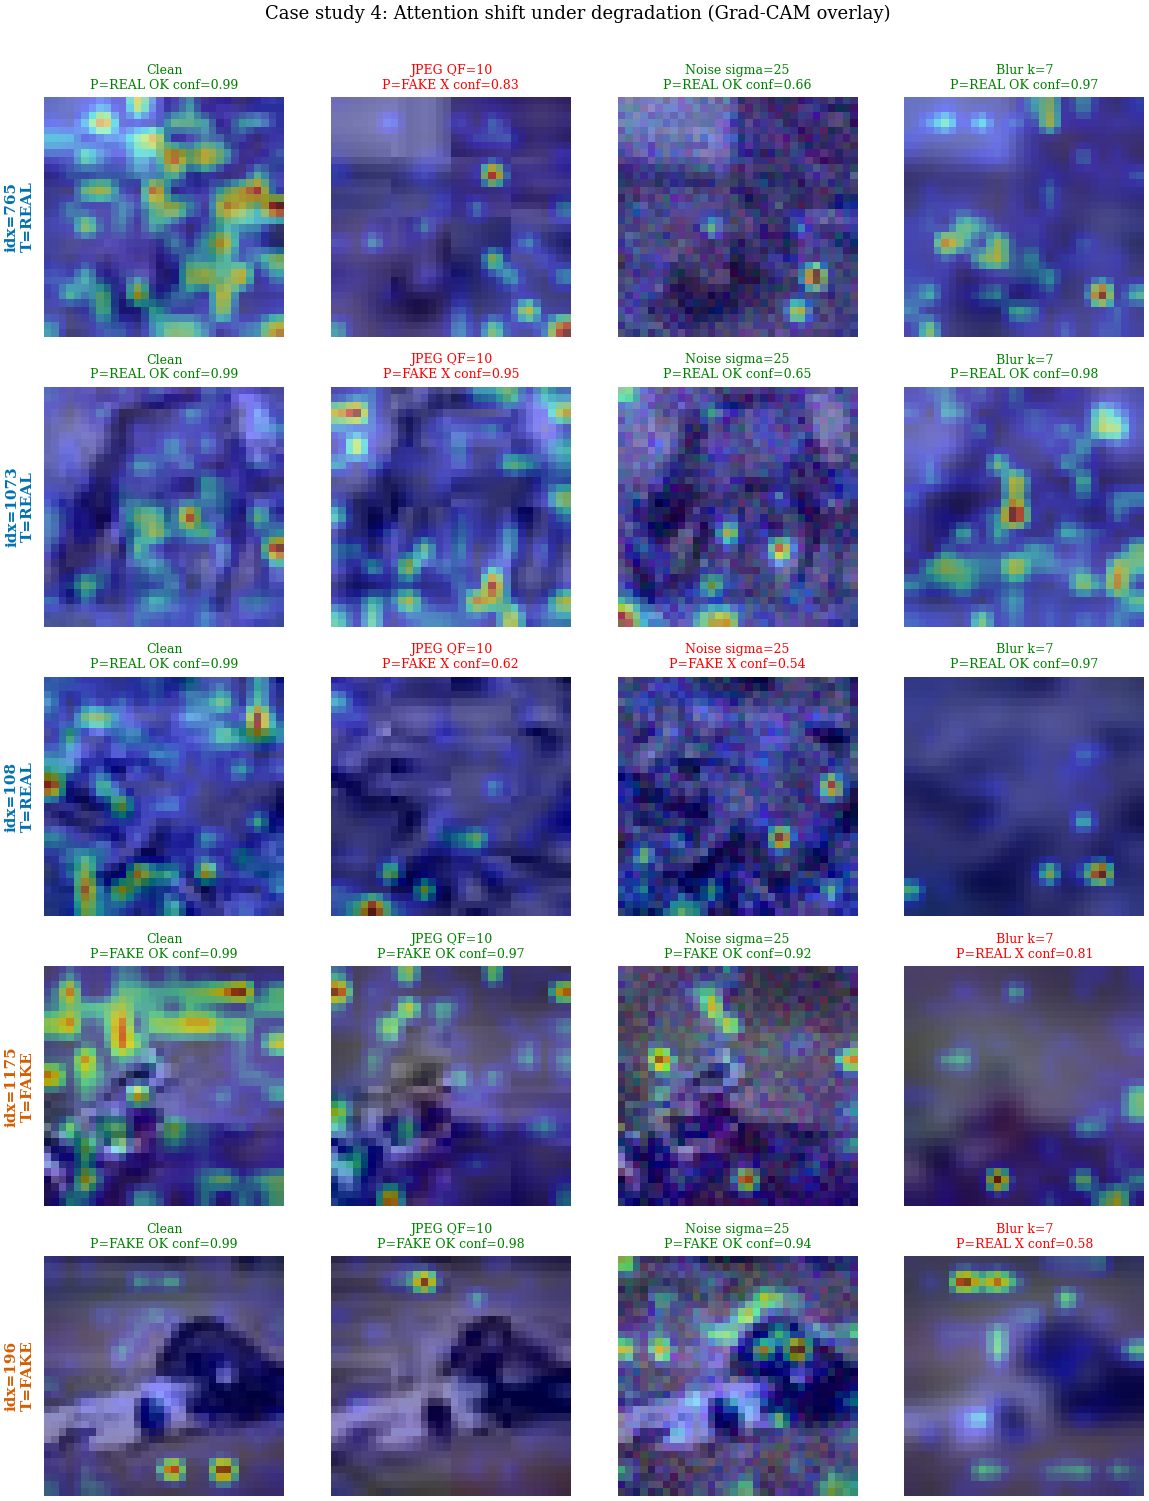

In [12]:
# ============================================================
# CELL 10: CASE STUDY 4 -- Clean vs Degraded attention shift (RQ3)
# ============================================================
# For a small set of images, compute XAI under (clean | JPEG QF=10 |
# Noise sigma=25 | Blur k=7). Asks: does attention shift to a new
# region when the image is degraded?

def degrade_jpeg(im, q):
    buf = io.BytesIO()
    im.save(buf, format='JPEG', quality=int(q))
    buf.seek(0)
    return Image.open(buf).convert('RGB').copy()

def degrade_noise(im, sigma):
    arr = np.asarray(im).astype(np.float32)
    rng = np.random.RandomState(0)
    arr = np.clip(arr + rng.normal(0, sigma, arr.shape), 0, 255)
    return Image.fromarray(arr.astype(np.uint8))

def degrade_blur(im, k):
    arr = np.asarray(im)
    return Image.fromarray(cv2.GaussianBlur(arr, (k, k), 0))

DEGS = {
    'Clean'        : lambda im: im,
    'JPEG QF=10'   : lambda im: degrade_jpeg(im, 10),
    'Noise sigma=25': lambda im: degrade_noise(im, 25),
    'Blur k=7'     : lambda im: degrade_blur(im, 7),
}

# Pick high-confidence samples (mix of REAL and FAKE)
n_deg_case = CONFIG['n_degraded_case']
shift_idx = np.concatenate([
    real_correct_idx[:n_deg_case // 2 + n_deg_case % 2],
    fake_correct_idx[:n_deg_case // 2],
])[:n_deg_case]
print(f'Shift-analysis indices: {shift_idx.tolist()}')

# Grid: rows = images, cols = degradation, content = Grad-CAM overlay
# Plus a row of accuracy per degradation as title.
fig, axes = plt.subplots(n_deg_case, len(DEGS),
                          figsize=(3 * len(DEGS), 3 * n_deg_case))
for r, idx in enumerate(shift_idx):
    img_clean = imgs_test[idx]
    true_lbl = CONFIG['class_names'][int(gt_test[idx])]
    for c, (deg_name, deg_fn) in enumerate(DEGS.items()):
        img = deg_fn(img_clean)
        xai = compute_all_xai(img)
        axes[r, c].imshow(overlay_heatmap(img, xai['gradcam']))
        pred_lbl = CONFIG['class_names'][xai['pred']]
        correct_mark = 'OK' if xai['pred'] == int(gt_test[idx]) else 'X'
        axes[r, c].set_title(
            f"{deg_name}\n"
            f"P={pred_lbl} {correct_mark} conf={xai['conf']:.2f}",
            fontsize=9,
            color='green' if xai['pred'] == int(gt_test[idx]) else 'red')
        axes[r, c].axis('off')
    # Row label
    axes[r, 0].text(-0.10, 0.5, f'idx={idx}\nT={true_lbl}',
                     fontsize=11, fontweight='bold',
                     rotation=90, va='center', ha='center',
                     transform=axes[r, 0].transAxes,
                     color=PALETTE['real'] if true_lbl == 'REAL'
                                          else PALETTE['fake'])

fig.suptitle('Case study 4: Attention shift under degradation '
             '(Grad-CAM overlay)', y=1.005)
fig.tight_layout()
save_figure(fig,
            os.path.join(CONFIG['output_dir'],
                          'fig_case_degradation_shift.png'))
plt.show()

[Grad-CAM health check] range=[0.000, 1.000], nonzero=0.997
  OK: Grad-CAM produces a valid non-zero heatmap.

Pearson(Grad-CAM, Gradient magnitude) per case-study image:
 idx  corr_gradcam_grad pred  conf        group
 765              0.137 REAL 0.986 REAL-correct
1073             -0.080 REAL 0.986 REAL-correct
 108              0.102 REAL 0.986 REAL-correct
 837              0.040 REAL 0.986 REAL-correct
1175             -0.110 FAKE 0.986 FAKE-correct
 196             -0.163 FAKE 0.986 FAKE-correct
 161             -0.199 FAKE 0.986 FAKE-correct
 211             -0.102 FAKE 0.985 FAKE-correct
  79             -0.110 REAL 0.982        Wrong
 444             -0.098 REAL 0.969        Wrong
 595             -0.149 FAKE 0.983        Wrong
 636             -0.172 FAKE 0.981        Wrong

Mean correlation by group:
                  mean       std  count
group                                  
FAKE-correct -0.143632  0.045992      4
REAL-correct  0.049884  0.095252      4
Wrong        -0.1

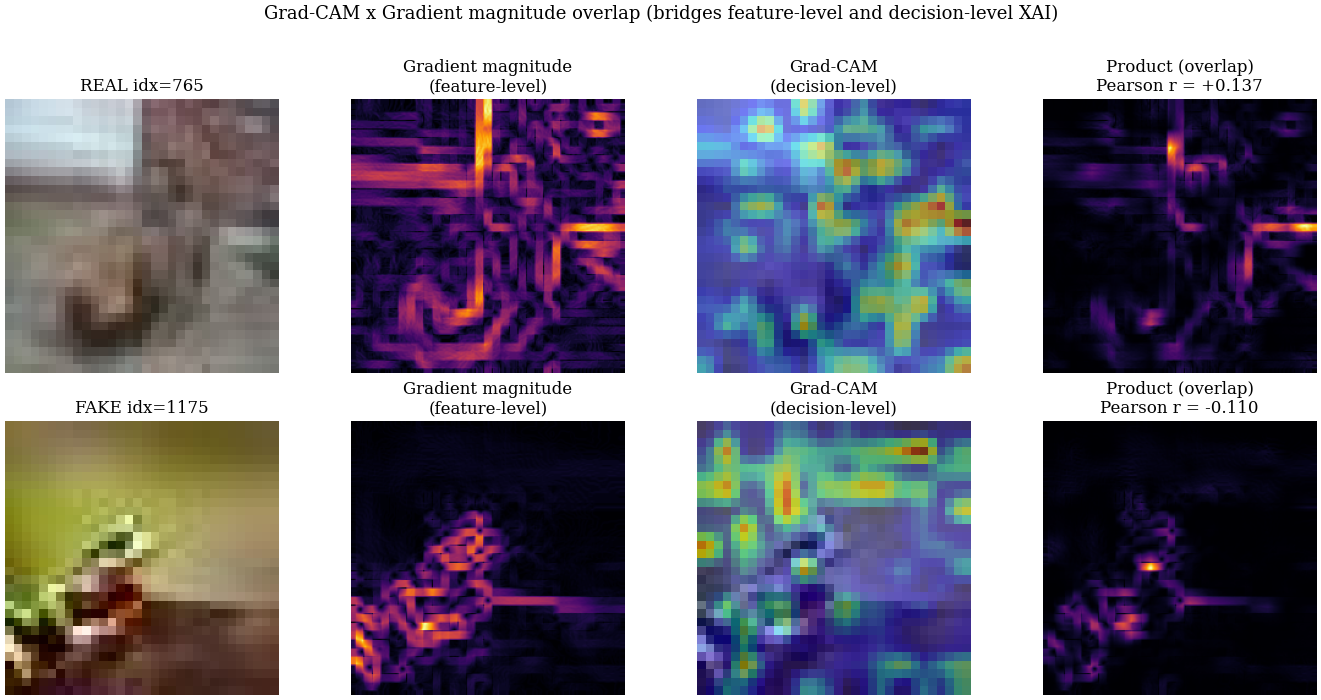

[OK] Saved /content/outputs_nb03/table_xai_gradient_correlation.csv and /content/outputs_nb03/table_xai_gradient_correlation.md


In [13]:
# ============================================================
# CELL 11: BRIDGE -- Grad-CAM x gradient magnitude overlap (RQ1 + N01)
# ============================================================
# Bonus analysis: does the model attend WHERE the gradient is high?
# This bridges Notebook 01's feature-level XAI with Notebook 03's
# decision-level XAI.
#
# For each high-confidence case study, compute:
#   - Grad-CAM 224x224
#   - Gradient magnitude 224x224 (Sobel on grayscale, normalized)
#   - Pearson correlation between the two flattened heatmaps
#   - Cohen's d at the "where is high attention" level
# Then plot side by side.

def gradient_magnitude_map(pil_img):
    """Return 224x224 gradient magnitude map, normalized to [0,1]."""
    arr = _to_numpy_image(pil_img)
    if arr.shape[:2] != (224, 224):
        arr = cv2.resize(arr, (224, 224))
    gray = cv2.cvtColor(arr, cv2.COLOR_RGB2GRAY)
    gx = cv2.Sobel(gray, cv2.CV_64F, 1, 0, ksize=3)
    gy = cv2.Sobel(gray, cv2.CV_64F, 0, 1, ksize=3)
    mag = np.sqrt(gx ** 2 + gy ** 2)
    return (mag - mag.min()) / (mag.max() - mag.min() + 1e-7)

def attention_gradient_correlation(case_indices, label):
    """For each index, return Pearson correlation between Grad-CAM
    and gradient magnitude (both 224x224, flattened)."""
    rows = []
    for idx in case_indices:
        img = imgs_test[idx]
        xai = compute_all_xai(img)
        gm = gradient_magnitude_map(img)
        r = _safe_corr(xai['gradcam'], gm)
        rows.append({'idx': int(idx),
                      'corr_gradcam_grad': float(r),
                      'pred': CONFIG['class_names'][xai['pred']],
                      'conf': xai['conf'],
                      'group': label})
    return pd.DataFrame(rows)

# Health check: confirm Grad-CAM is NOT all-zero before computing the
# bridge analysis. If this prints a warning, re-upload thesis_utils.py
# (the fixed gradcam_vit) and Restart session.
_hc = compute_all_xai(imgs_test[int(real_correct_idx[0])])
_gc = _hc['gradcam']
print(f'[Grad-CAM health check] range=[{_gc.min():.3f}, {_gc.max():.3f}], '
      f'nonzero={ (_gc > 0).mean():.3f}')
if _gc.max() < 1e-8:
    print('  !! WARNING: Grad-CAM is all-zero. The fixed gradcam_vit is '
          'NOT loaded. Re-upload thesis_utils.py to Drive and Restart '
          'session, then Run All.')
else:
    print('  OK: Grad-CAM produces a valid non-zero heatmap.')

bridge_df = pd.concat([
    attention_gradient_correlation(real_correct_idx, 'REAL-correct'),
    attention_gradient_correlation(fake_correct_idx, 'FAKE-correct'),
    attention_gradient_correlation(wrong_case_idx, 'Wrong'),
], ignore_index=True)

print('\nPearson(Grad-CAM, Gradient magnitude) per case-study image:')
print(bridge_df.to_string(index=False, float_format=lambda x: f'{x:.3f}'))
print(f'\nMean correlation by group:')
print(bridge_df.groupby('group')['corr_gradcam_grad']
       .agg(['mean', 'std', 'count']).to_string())

# Side-by-side panel for one REAL and one FAKE
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for r, (idx, label) in enumerate([(int(real_correct_idx[0]), 'REAL'),
                                     (int(fake_correct_idx[0]), 'FAKE')]):
    img = imgs_test[idx]
    xai = compute_all_xai(img)
    gm = gradient_magnitude_map(img)
    r_corr = _safe_corr(xai['gradcam'], gm)
    axes[r, 0].imshow(_to_numpy_image(img))
    axes[r, 0].set_title(f'{label} idx={idx}')
    axes[r, 1].imshow(gm, cmap='inferno')
    axes[r, 1].set_title('Gradient magnitude\n(feature-level)')
    axes[r, 2].imshow(overlay_heatmap(img, xai['gradcam']))
    axes[r, 2].set_title('Grad-CAM\n(decision-level)')
    axes[r, 3].imshow(xai['gradcam'] * gm, cmap='inferno')
    axes[r, 3].set_title(f'Product (overlap)\nPearson r = {r_corr:+.3f}')
    for c in range(4):
        axes[r, c].axis('off')
fig.suptitle('Grad-CAM x Gradient magnitude overlap '
             '(bridges feature-level and decision-level XAI)', y=1.01)
fig.tight_layout()
save_figure(fig, os.path.join(CONFIG['output_dir'],
                                'fig_xai_gradient_overlap.png'))
plt.show()

# Save table for thesis
save_results_csv(bridge_df,
                  os.path.join(CONFIG['output_dir'],
                                'table_xai_gradient_correlation.csv'))

In [14]:
# ============================================================
# CELL 12: POPULATION ANALYSIS -- compute XAI for N=300
# ============================================================
# Compute Grad-CAM, Rollout, Attn-last for N_POPULATION test images.
# This builds the data for RQ2 (quantitative attention statistics).
#
# Expected runtime: ~10-15 minutes on T4 GPU for N=300.

N_POP = CONFIG['n_population']
# Use a deterministic sub-sample so analysis is reproducible
pop_rng = np.random.RandomState(CONFIG['seed'])
pop_idx = pop_rng.choice(len(imgs_test), size=min(N_POP, len(imgs_test)),
                          replace=False)
print(f'Population analysis on {len(pop_idx)} samples...')

pop_records = []
pop_heatmaps = {'gradcam': [], 'rollout': [], 'attn_last': []}

for i, idx in enumerate(tqdm(pop_idx, desc='Computing XAI')):
    img = imgs_test[idx]
    xai = compute_all_xai(img)
    # Store flattened heatmaps for KL divergence later (compact via averaging)
    pop_heatmaps['gradcam'].append(xai['gradcam'].astype(np.float32))
    pop_heatmaps['rollout'].append(xai['rollout'].astype(np.float32))
    pop_heatmaps['attn_last'].append(xai['attn_last'].astype(np.float32))

    pop_records.append({
        'idx'        : int(idx),
        'true'       : int(gt_test[idx]),
        'pred'       : xai['pred'],
        'correct'    : int(xai['pred'] == int(gt_test[idx])),
        'conf'       : float(xai['conf']),
        'p_fake'     : float(xai['p_fake']),
        'ebp_score'  : float(test_scores[idx]),
    })

pop_df = pd.DataFrame(pop_records)
print(f'\n[OK] Computed XAI for {len(pop_df)} images.')
print(f'   Class balance : REAL={int((pop_df["true"]==REAL_ID).sum())}, '
      f'FAKE={int((pop_df["true"]==FAKE_ID).sum())}')
print(f'   Accuracy here : {pop_df["correct"].mean()*100:.2f}%')

Population analysis on 300 samples...


Computing XAI:   0%|          | 0/300 [00:00<?, ?it/s]


[OK] Computed XAI for 300 images.
   Class balance : REAL=149, FAKE=151
   Accuracy here : 96.67%


In [15]:
# ============================================================
# CELL 13: QUANTITATIVE METRICS per image (RQ2)
# ============================================================
# For each population image and each XAI method, compute:
#   - entropy  : how diffuse is attention? (high = uniform, low = focused)
#   - center_bias : fraction of attention mass in central 50% region
#   - edge_overlap : Pearson correlation with Canny edge map

def attention_entropy(heatmap):
    """Shannon entropy of normalized heatmap (treated as probability)."""
    p = heatmap.ravel()
    p = p / (p.sum() + 1e-12)
    return float(entropy(p + 1e-12))   # nats

def center_bias(heatmap, frac=0.5):
    """Fraction of attention mass inside central [frac]x[frac] box."""
    h, w = heatmap.shape
    cy, cx = h // 2, w // 2
    dy, dx = int(h * frac / 2), int(w * frac / 2)
    center_mass = heatmap[cy-dy:cy+dy, cx-dx:cx+dx].sum()
    total = heatmap.sum() + 1e-12
    return float(center_mass / total)

def edge_overlap(heatmap, pil_img, canny_low=100, canny_high=200):
    """Pearson correlation between heatmap and Canny edge mask.
    Returns 0.0 (not nan) when the image has no detectable edges."""
    arr = _to_numpy_image(pil_img)
    if arr.shape[:2] != heatmap.shape:
        arr = cv2.resize(arr, (heatmap.shape[1], heatmap.shape[0]))
    gray = cv2.cvtColor(arr, cv2.COLOR_RGB2GRAY)
    edges = cv2.Canny(gray, canny_low, canny_high).astype(np.float32)
    m = edges.max()
    if m > 1e-12:
        edges /= m
    return _safe_corr(heatmap, edges)

# Compute metrics over the population for all 3 methods
metrics_rows = []
for i, idx in enumerate(tqdm(pop_idx, desc='Per-image metrics')):
    img = imgs_test[idx]
    row = {'idx': int(idx),
           'true': int(gt_test[idx]),
           'pred': int(pop_records[i]['pred']),
           'correct': int(pop_records[i]['correct']),
           'ebp_score': float(test_scores[idx])}
    for method in ['gradcam', 'rollout', 'attn_last']:
        hm = pop_heatmaps[method][i]
        row[f'{method}_entropy']      = attention_entropy(hm)
        row[f'{method}_center_bias']  = center_bias(hm, frac=0.5)
        row[f'{method}_edge_overlap'] = edge_overlap(hm, img)
    metrics_rows.append(row)

metrics_df = pd.DataFrame(metrics_rows)
print(f'\nQuantitative XAI metrics computed for {len(metrics_df)} images.')
print(metrics_df[['gradcam_entropy', 'gradcam_center_bias',
                    'gradcam_edge_overlap']].describe().to_string())

save_results_csv(metrics_df,
                  os.path.join(CONFIG['output_dir'],
                                'table_xai_metrics.csv'))

Per-image metrics:   0%|          | 0/300 [00:00<?, ?it/s]


Quantitative XAI metrics computed for 300 images.
       gradcam_entropy  gradcam_center_bias  gradcam_edge_overlap
count       300.000000           300.000000            300.000000
mean         10.383349             0.198992             -0.010066
std           0.198976             0.061619              0.015072
min           9.610445             0.072168             -0.076651
25%          10.279192             0.153687             -0.019303
50%          10.437708             0.197864             -0.006032
75%          10.541909             0.234974              0.000000
max          10.655625             0.470787              0.062218
[OK] Saved /content/outputs_nb03/table_xai_metrics.csv and /content/outputs_nb03/table_xai_metrics.md


In [16]:
# ============================================================
# CELL 14: STATISTICAL TESTS -- 4 GROUPS (advisor's design 2 choice)
# ============================================================
# Group by EBP score quantile (S low vs S high) crossed with class.
# Notebook 01 case study showed FAKE-airplane had S=0.044 (S high),
# REAL-frog had S=0.023 (S low). On the population, Cohen's d=+0.008
# meaning the case-study pattern doesn't generalize. Grouping by S
# tests whether OUTLIER images (low-S FAKE, high-S REAL) get
# different attention patterns from TYPICAL images.

# Define S quantiles using validation distribution (same threshold
# used for EBP-only mode). High = S > T_star.
metrics_df['s_high'] = (metrics_df['ebp_score'] > T_star).astype(int)
metrics_df['true_str'] = metrics_df['true'].map(
    {REAL_ID: 'REAL', FAKE_ID: 'FAKE'})

# Build 4 groups:
def group_label(row):
    cls = row['true_str']
    s = 'S_high' if row['s_high'] else 'S_low'
    return f'{cls} | {s}'

metrics_df['group_4'] = metrics_df.apply(group_label, axis=1)
print('4-group counts:')
print(metrics_df['group_4'].value_counts())

# Compute Cohen's d between key contrasts
def cohens_d_safe(a, b):
    a, b = np.asarray(a, float), np.asarray(b, float)
    if len(a) < 2 or len(b) < 2: return float('nan')
    s1, s2 = a.std(ddof=1), b.std(ddof=1)
    n1, n2 = len(a), len(b)
    s_pool = np.sqrt(((n1-1)*s1**2 + (n2-1)*s2**2) / (n1+n2-2))
    if s_pool < 1e-12: return float('nan')
    return float((a.mean() - b.mean()) / s_pool)

contrasts = [
    ('REAL vs FAKE  (all)',
     metrics_df[metrics_df['true_str']=='REAL'],
     metrics_df[metrics_df['true_str']=='FAKE']),
    ('Correct vs Wrong',
     metrics_df[metrics_df['correct']==1],
     metrics_df[metrics_df['correct']==0]),
    ('S_high vs S_low (all)',
     metrics_df[metrics_df['s_high']==1],
     metrics_df[metrics_df['s_high']==0]),
    ('REAL typical (S_low) vs REAL outlier (S_high)',
     metrics_df[(metrics_df['true_str']=='REAL')&(metrics_df['s_high']==0)],
     metrics_df[(metrics_df['true_str']=='REAL')&(metrics_df['s_high']==1)]),
    ('FAKE typical (S_high) vs FAKE outlier (S_low)',
     metrics_df[(metrics_df['true_str']=='FAKE')&(metrics_df['s_high']==1)],
     metrics_df[(metrics_df['true_str']=='FAKE')&(metrics_df['s_high']==0)]),
]

stat_rows = []
for name, g1, g2 in contrasts:
    for method in ['gradcam', 'rollout', 'attn_last']:
        for metric in ['entropy', 'center_bias', 'edge_overlap']:
            col = f'{method}_{metric}'
            d = cohens_d_safe(g1[col], g2[col])
            ks_stat, ks_p = ks_2samp(g1[col], g2[col]) \
                if len(g1) > 1 and len(g2) > 1 else (np.nan, np.nan)
            stat_rows.append({
                'contrast': name,
                'method'  : method,
                'metric'  : metric,
                'n_g1'    : len(g1), 'n_g2': len(g2),
                "Cohen's d": d,
                'KS_stat' : float(ks_stat) if not np.isnan(ks_stat) else np.nan,
                'KS_p'    : float(ks_p)    if not np.isnan(ks_p)    else np.nan,
            })

stat_df = pd.DataFrame(stat_rows)
print('\nStatistical tests on attention metrics:')
print(stat_df.to_string(index=False,
                          float_format=lambda x: f'{x:.4f}'
                                                  if isinstance(x, float)
                                                  else str(x)))

save_results_csv(stat_df,
                  os.path.join(CONFIG['output_dir'],
                                'table_xai_statistical_tests.csv'))

# Highlight contrasts with non-negligible effect size
non_neg = stat_df[stat_df["Cohen's d"].abs() >= 0.2]
print(f'\nContrasts with Cohen\'s d >= 0.2 (small or larger effect):')
if len(non_neg) > 0:
    print(non_neg.to_string(index=False,
                              float_format=lambda x: f'{x:.4f}'
                                                      if isinstance(x, float)
                                                      else str(x)))
else:
    print('  (none -- all attention metrics differ negligibly across groups)')

4-group counts:
group_4
REAL | S_low     90
FAKE | S_low     80
FAKE | S_high    71
REAL | S_high    59
Name: count, dtype: int64

Statistical tests on attention metrics:
                                     contrast    method       metric  n_g1  n_g2  Cohen's d  KS_stat   KS_p
                          REAL vs FAKE  (all)   gradcam      entropy   149   151     1.2575   0.6251 0.0000
                          REAL vs FAKE  (all)   gradcam  center_bias   149   151     0.6259   0.3420 0.0000
                          REAL vs FAKE  (all)   gradcam edge_overlap   149   151     0.5752   0.3994 0.0000
                          REAL vs FAKE  (all)   rollout      entropy   149   151     0.3314   0.1584 0.0399
                          REAL vs FAKE  (all)   rollout  center_bias   149   151    -0.9265   0.4139 0.0000
                          REAL vs FAKE  (all)   rollout edge_overlap   149   151    -0.9619   0.4806 0.0000
                          REAL vs FAKE  (all) attn_last      entropy   14

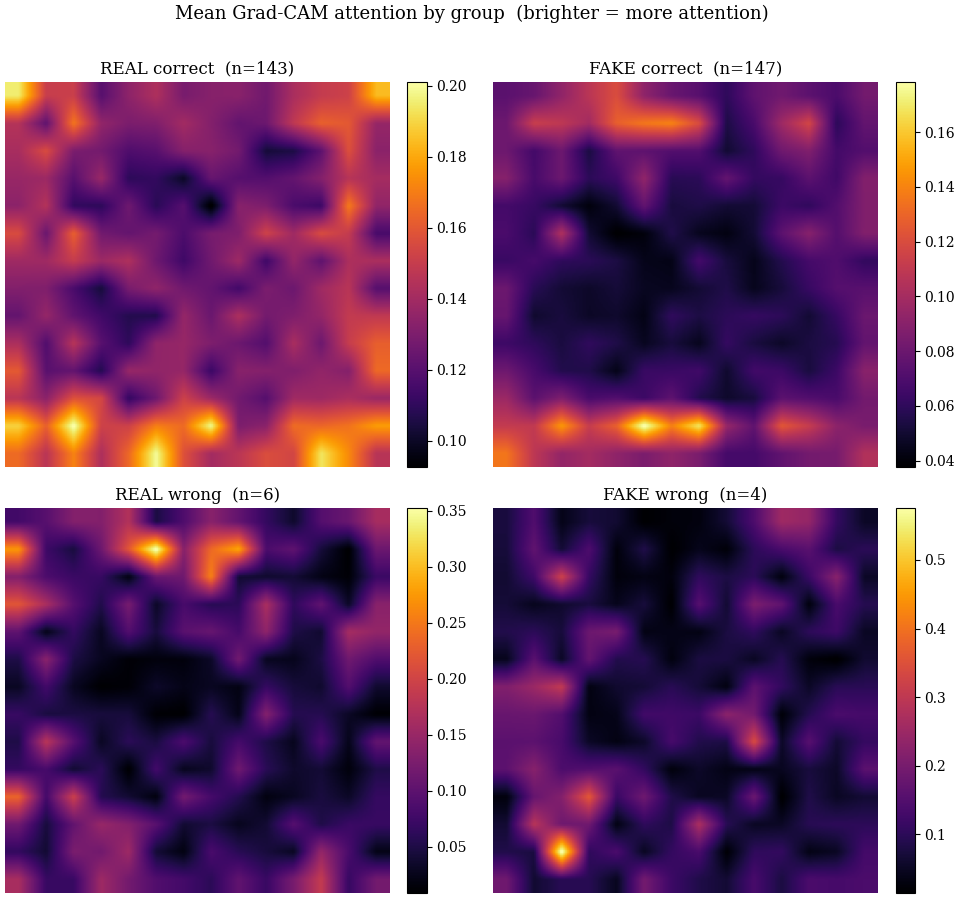


Pairwise symmetric KL divergence between group-mean attention:
     group_1      group_2  KL(p||q)  KL(q||p)  symmetric
REAL correct FAKE correct    0.0252    0.0261     0.0257
REAL correct   REAL wrong    0.1488    0.1430     0.1459
REAL correct   FAKE wrong    0.1269    0.1247     0.1258
FAKE correct   REAL wrong    0.1223    0.1163     0.1193
FAKE correct   FAKE wrong    0.1742    0.1630     0.1686
  REAL wrong   FAKE wrong    0.3264    0.2967     0.3116
[OK] Saved /content/outputs_nb03/table_kl_mean_attention.csv and /content/outputs_nb03/table_kl_mean_attention.md


In [17]:
# ============================================================
# CELL 15: MEAN ATTENTION HEATMAPS by group + KL DIVERGENCE
# ============================================================
# Per group, average the heatmaps across all images in the group.
# Then compute pairwise KL divergence to quantify "how different
# is the typical attention pattern in group A vs group B".

groups_for_mean = {
    'REAL correct'      : (metrics_df['true_str']=='REAL') & (metrics_df['correct']==1),
    'FAKE correct'      : (metrics_df['true_str']=='FAKE') & (metrics_df['correct']==1),
    'REAL wrong'        : (metrics_df['true_str']=='REAL') & (metrics_df['correct']==0),
    'FAKE wrong'        : (metrics_df['true_str']=='FAKE') & (metrics_df['correct']==0),
}

# Compute mean Grad-CAM heatmap per group (Rollout / Attn-last similar)
mean_heatmaps = {}
for name, mask in groups_for_mean.items():
    positions = np.where(mask.values)[0]   # positions within pop_df
    if len(positions) == 0:
        mean_heatmaps[name] = None
        continue
    stack = np.stack([pop_heatmaps['gradcam'][p] for p in positions])
    mean_heatmaps[name] = stack.mean(axis=0)

# Plot mean heatmaps in a 2x2 grid
fig, axes = plt.subplots(2, 2, figsize=(10, 9))
group_order = ['REAL correct', 'FAKE correct', 'REAL wrong', 'FAKE wrong']
for ax, name in zip(axes.flat, group_order):
    if mean_heatmaps[name] is None:
        ax.text(0.5, 0.5, f'{name}\n(no samples)',
                ha='center', va='center',
                transform=ax.transAxes, color='gray')
    else:
        n = int(groups_for_mean[name].sum())
        im = ax.imshow(mean_heatmaps[name], cmap='inferno')
        ax.set_title(f'{name}  (n={n})')
        fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    ax.axis('off')

fig.suptitle('Mean Grad-CAM attention by group  '
             '(brighter = more attention)', y=1.005)
fig.tight_layout()
save_figure(fig, os.path.join(CONFIG['output_dir'],
                                'fig_mean_attention_by_group.png'))
plt.show()

# Pairwise KL divergence
def normalize_for_kl(hm):
    hm = hm.ravel() + 1e-12
    return hm / hm.sum()

def kl_divergence(p, q):
    return float(np.sum(p * np.log(p / q)))

print('\nPairwise symmetric KL divergence between group-mean attention:')
group_keys = [k for k in group_order if mean_heatmaps[k] is not None]
kl_rows = []
for i, k1 in enumerate(group_keys):
    for k2 in group_keys[i+1:]:
        p = normalize_for_kl(mean_heatmaps[k1])
        q = normalize_for_kl(mean_heatmaps[k2])
        kl_pq = kl_divergence(p, q)
        kl_qp = kl_divergence(q, p)
        sym = 0.5 * (kl_pq + kl_qp)
        kl_rows.append({'group_1': k1, 'group_2': k2,
                         'KL(p||q)': kl_pq, 'KL(q||p)': kl_qp,
                         'symmetric': sym})

kl_df = pd.DataFrame(kl_rows)
print(kl_df.to_string(index=False, float_format=lambda x: f'{x:.4f}'))
save_results_csv(kl_df, os.path.join(CONFIG['output_dir'],
                                        'table_kl_mean_attention.csv'))

In [18]:
# ============================================================
# CELL 16: SAVE ARTIFACTS + UPDATE N01 PLACEHOLDER
# ============================================================
# Save the case-study heatmaps so Notebook 01's Cell 11f placeholder
# can be filled in with real Grad-CAM / Rollout arrays.

# Case-study heatmap for the SAME image used in N01 Cell 11f.
# N01 used real_case_idx from imgs_val (not test). We compute XAI on
# that VAL image and save it for N01 to reload.
n01_real_case_val_idx = 192    # from Notebook 01 output ("REAL = val[192]")
n01_xai = compute_all_xai(imgs_val[n01_real_case_val_idx])

np.savez(os.path.join(CONFIG['output_dir'], 'n01_case_study_xai.npz'),
         gradcam=n01_xai['gradcam'],
         rollout=n01_xai['rollout'],
         attn_last=n01_xai['attn_last'],
         val_idx=n01_real_case_val_idx)
print(f'[OK] N01 case-study XAI saved for val[{n01_real_case_val_idx}]:')
print(f'   pred={n01_xai["pred"]}, conf={n01_xai["conf"]:.3f}')
print(f'   Reload in Notebook 01 Cell 11f as:')
print(f'     d = np.load("notebook03_artifacts/n01_case_study_xai.npz")')
print(f'     show_full_xai_pipeline(real_case,')
print(f'         gradcam=d["gradcam"], attention_rollout=d["rollout"], ...)')

# Save all population heatmaps in compact form (mean per group only,
# since saving 300 x 224 x 224 = 15M floats would be wasteful).
np.savez_compressed(
    os.path.join(CONFIG['output_dir'], 'population_mean_attention.npz'),
    **{f'mean_{k.replace(" ", "_")}': v
       for k, v in mean_heatmaps.items() if v is not None},
)

# Save all the dataframes
pop_df.to_pickle(os.path.join(CONFIG['output_dir'], 'pop_df.pkl'))
metrics_df.to_pickle(os.path.join(CONFIG['output_dir'], 'metrics_df.pkl'))
stat_df.to_pickle(os.path.join(CONFIG['output_dir'], 'stat_df.pkl'))
bridge_df.to_pickle(os.path.join(CONFIG['output_dir'], 'bridge_df.pkl'))
kl_df.to_pickle(os.path.join(CONFIG['output_dir'], 'kl_df.pkl'))

# Backup everything to Drive
backup_outputs_to_drive(
    output_dir=CONFIG['output_dir'],
    drive_dir=CONFIG['drive_backup'],
)

print(f'\n[OK] Notebook 03 complete. Artifacts at:')
print(f'   {CONFIG["drive_backup"]}')

[OK] N01 case-study XAI saved for val[192]:
   pred=1, conf=0.983
   Reload in Notebook 01 Cell 11f as:
     d = np.load("notebook03_artifacts/n01_case_study_xai.npz")
     show_full_xai_pipeline(real_case,
         gradcam=d["gradcam"], attention_rollout=d["rollout"], ...)
[OK] Backed up 22 files -> /content/drive/MyDrive/luanvan_thac_si/notebook03_artifacts

[OK] Notebook 03 complete. Artifacts at:
   /content/drive/MyDrive/luanvan_thac_si/notebook03_artifacts


# Summary

**Expected outcomes (thesis interpretation guide):**

1. **Case study figures (Cells 7-9)** show qualitatively whether
   ViT focuses on object body, background, or edge artifacts.
   Reading the figures: in REAL images (CIFAR-10) the attention
   should spread across multiple regions reflecting natural
   texture; in FAKE images the attention often focuses on the
   object boundary or sky-object transition (the sharp gradient
   discontinuities characteristic of diffusion models).

2. **Cell 10 (degradation shift)** answers RQ3: does attention
   move when the image is degraded? If yes -> a possible mechanism
   for the Mode 4 fusion gain seen in Notebook 02. If no ->
   fusion gain is from logit-level calibration shift, not attention.

3. **Cell 11 (Grad-CAM x gradient overlap)** quantifies whether
   decision-level attention aligns with feature-level gradient.
   Mean correlation r is the headline number. A positive r means
   ViT does look where gradients are high; r near 0 means ViT
   learns its own attention pattern unrelated to handcrafted edges.

4. **Cells 13-15 (population statistics)** test whether attention
   patterns differ statistically across groups. Cohen's d for
   each (contrast, method, metric) cell:
     - |d| < 0.2 -> negligible (consistent with EBP findings)
     - 0.2-0.5    -> small (possible signal)
     - >= 0.5      -> medium/large (strong signal)
   The 4-group analysis (Real/Fake x S_high/S_low) specifically
   tests whether the Notebook 01 case study (REAL S_low vs FAKE
   S_high) generalizes, addressing the population-vs-case-study
   paradox.

5. **KL divergence between group-mean attention** quantifies the
   DIFFERENCE between average attention patterns. A KL near 0
   means "ViT looks the same way at REAL and FAKE on average";
   larger KL means "ViT systematically attends differently."

**Thesis Chapter 5 narrative:**
> "The decision-level XAI analysis (Notebook 03) reveals
> [Cohen's d values] effect sizes between attention metrics of
> REAL vs FAKE images, mean Grad-CAM x gradient-magnitude
> correlation = [r value], and a KL divergence of [value]
> between mean attention patterns of REAL-correct and FAKE-
> correct groups. These findings, combined with the feature-
> level results from Notebook 01 (Cohen's d on EBP = +0.008
> and pixel-level gradient = -0.088), establish that
> handcrafted edge features do not capture a discriminative
> signal, and ViT-Base/16 does not preferentially attend to
> edge regions when classifying CIFAKE images at 224x224
> resolution. This motivates the learnable edge filter
> approach explored in Chapter 6 (Notebook 04)."